# skin 1단계-2번 — 하이퍼파라미터 튜닝 데모

**순서**: Early Stopping(완료, Sensitivity 0.367→0.567) → **하이퍼파라미터 튜닝(이 노트북)** → 모델 구조 개선.

**배경**: Early Stopping 실험에서 fold마다 1~2 epoch 만에 멈췄습니다 — 이건 "학습이 끝나서"가 아니라
**learning rate가 너무 커서 너무 빨리 train 데이터를 외워버리는 것**일 수 있습니다. 그래서 이번엔
`hidden_dim`(모델 크기)과 `learning rate`(학습 속도)를 같이 바꿔가며 탐색합니다.

**탐색 범위**:
- `hidden_dim`: 64 / 128(기존 기본값) / 256
- `learning_rate`: 0.01 / 0.001(기존 기본값) / 0.0001

9개 조합을 전부 **Early Stopping을 켠 채로** group 5-fold 평가합니다(1단계-1번에서 채택한 방식 위에서 비교해야
공정하기 때문입니다).

In [1]:
import sys
sys.path.insert(0, r"C:\Users\UserK\학술제\modeling\src")

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, roc_auc_score, matthews_corrcoef

from datasets import skin_dataset
from splits import grouped_kfold_splits
from train import class_weights, EarlyStopping

skin_ds = skin_dataset()
print(f"skin: {len(skin_ds)}건, feature {skin_ds.input_dim}차원")

skin: 541건, feature 2266차원


## 1. 모델 정의 (hidden_dim을 바꿀 수 있게)

In [2]:
class SkinOnlyModel(nn.Module):
    def __init__(self, input_dim, hidden_dim=128, num_classes=2, dropout=0.2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden_dim, hidden_dim), nn.ReLU(),
            nn.Linear(hidden_dim, num_classes),
        )

    def forward(self, x):
        return self.net(x)

## 2. Early Stopping 포함 학습 함수 (1단계-1번과 동일 로직, hidden_dim/lr을 인자로 받음)

In [3]:
def fit_early_stopping(X_train, y_train, X_test, seed, hidden_dim=128, lr=1e-3,
                        max_epochs=200, patience=15, batch_size=32, val_size=0.2):
    rng_split = np.random.default_rng(seed)
    n = len(X_train)
    idx = rng_split.permutation(n)
    n_val = max(1, int(n * val_size))
    val_pos, train_pos = idx[:n_val], idx[n_val:]

    torch.manual_seed(seed)
    model = SkinOnlyModel(X_train.shape[1], hidden_dim=hidden_dim)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss(weight=class_weights(y_train[train_pos]))

    Xt = torch.from_numpy(X_train[train_pos].astype(np.float32))
    yt = torch.from_numpy(y_train[train_pos].astype(np.int64))
    Xv = torch.from_numpy(X_train[val_pos].astype(np.float32))
    yv = torch.from_numpy(y_train[val_pos].astype(np.int64))

    stopper = EarlyStopping(patience=patience)
    for epoch in range(max_epochs):
        model.train()
        perm = torch.randperm(len(Xt))
        for i in range(0, len(Xt), batch_size):
            b = perm[i:i + batch_size]
            optimizer.zero_grad()
            loss = criterion(model(Xt[b]), yt[b])
            loss.backward()
            optimizer.step()
        model.eval()
        with torch.no_grad():
            val_loss = criterion(model(Xv), yv).item()
        if stopper.step(val_loss, epoch, model):
            break
    model.load_state_dict(stopper.best_state)

    model.eval()
    with torch.no_grad():
        proba = torch.softmax(model(torch.from_numpy(X_test.astype(np.float32))), dim=1)[:, 1].numpy()
    return proba, stopper.best_epoch + 1

## 3. hidden_dim x learning_rate 9개 조합 탐색 (group 5-fold)

In [4]:
def run_cv(hidden_dim, lr, n_splits=5, random_state=0):
    folds = grouped_kfold_splits(skin_ds, n_splits=n_splits, random_state=random_state)
    oof = np.zeros(len(skin_ds.y))
    stop_epochs = []
    for fold_i, (train_idx, test_idx) in enumerate(folds):
        scaler = StandardScaler().fit(skin_ds.X[train_idx])
        X_train = scaler.transform(skin_ds.X[train_idx])
        X_test = scaler.transform(skin_ds.X[test_idx])
        proba, stop_ep = fit_early_stopping(X_train, skin_ds.y[train_idx], X_test, seed=fold_i,
                                             hidden_dim=hidden_dim, lr=lr)
        oof[test_idx] = proba
        stop_epochs.append(stop_ep)
    return oof, stop_epochs


def summarize(y_true, proba):
    pred = (proba >= 0.5).astype(int)
    cm = confusion_matrix(y_true, pred)
    tn, fp, fn, tp = cm.ravel()
    sens = tp / (tp + fn)
    spec = tn / (tn + fp)
    mcc = matthews_corrcoef(y_true, pred)
    roc = roc_auc_score(y_true, proba)
    gap = abs(sens - spec)
    return dict(sensitivity=sens, specificity=spec, gap=gap, mcc=mcc, roc_auc=roc)


HIDDEN_DIMS = [64, 128, 256]
LRS = [0.01, 0.001, 0.0001]

results = {}
for hd in HIDDEN_DIMS:
    for lr in LRS:
        oof, stop_epochs = run_cv(hd, lr)
        res = summarize(skin_ds.y, oof)
        res["avg_stop_epoch"] = np.mean(stop_epochs)
        results[(hd, lr)] = res
        print(f"hidden_dim={hd:3d} lr={lr:<7} -> Sens {res['sensitivity']:.3f} / Spec {res['specificity']:.3f} / "
              f"격차 {res['gap']:.3f} / MCC {res['mcc']:.3f} / ROC-AUC {res['roc_auc']:.3f} / "
              f"평균 종료epoch {res['avg_stop_epoch']:.1f}")

hidden_dim= 64 lr=0.01    -> Sens 0.600 / Spec 0.800 / 격차 0.200 / MCC 0.221 / ROC-AUC 0.741 / 평균 종료epoch 1.4
hidden_dim= 64 lr=0.001   -> Sens 0.533 / Spec 0.885 / 격차 0.351 / MCC 0.277 / ROC-AUC 0.801 / 평균 종료epoch 2.0
hidden_dim= 64 lr=0.0001  -> Sens 0.567 / Spec 0.855 / 격차 0.289 / MCC 0.258 / ROC-AUC 0.765 / 평균 종료epoch 13.0
hidden_dim=128 lr=0.01    -> Sens 0.633 / Spec 0.800 / 격차 0.167 / MCC 0.238 / ROC-AUC 0.778 / 평균 종료epoch 1.4
hidden_dim=128 lr=0.001   -> Sens 0.567 / Spec 0.847 / 격차 0.281 / MCC 0.249 / ROC-AUC 0.762 / 평균 종료epoch 1.2
hidden_dim=128 lr=0.0001  -> Sens 0.567 / Spec 0.814 / 격차 0.247 / MCC 0.215 / ROC-AUC 0.762 / 평균 종료epoch 8.2
hidden_dim=256 lr=0.01    -> Sens 0.400 / Spec 0.824 / 격차 0.424 / MCC 0.131 / ROC-AUC 0.682 / 평균 종료epoch 1.6
hidden_dim=256 lr=0.001   -> Sens 0.467 / Spec 0.857 / 격차 0.390 / MCC 0.202 / ROC-AUC 0.717 / 평균 종료epoch 1.2
hidden_dim=256 lr=0.0001  -> Sens 0.467 / Spec 0.892 / 격차 0.426 / MCC 0.246 / ROC-AUC 0.722 / 평균 종료epoch 6.0


## 4. 결과 시각화 — MCC 히트맵 + 평균 종료 epoch

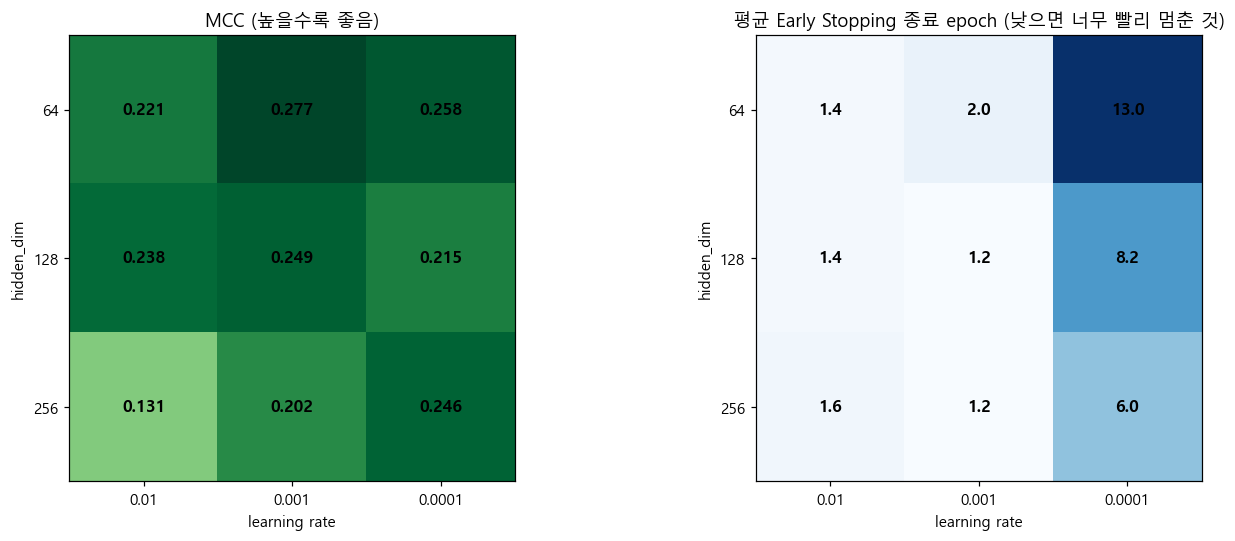

In [5]:
import matplotlib.pyplot as plt

mcc_grid = np.array([[results[(hd, lr)]["mcc"] for lr in LRS] for hd in HIDDEN_DIMS])
epoch_grid = np.array([[results[(hd, lr)]["avg_stop_epoch"] for lr in LRS] for hd in HIDDEN_DIMS])

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

im0 = axes[0].imshow(mcc_grid, cmap="YlGn", vmin=0)
axes[0].set_xticks(range(len(LRS))); axes[0].set_xticklabels([str(lr) for lr in LRS])
axes[0].set_yticks(range(len(HIDDEN_DIMS))); axes[0].set_yticklabels([str(hd) for hd in HIDDEN_DIMS])
axes[0].set_xlabel("learning rate"); axes[0].set_ylabel("hidden_dim")
axes[0].set_title("MCC (높을수록 좋음)")
for i in range(len(HIDDEN_DIMS)):
    for j in range(len(LRS)):
        axes[0].text(j, i, f"{mcc_grid[i,j]:.3f}", ha="center", va="center", fontsize=11, fontweight="bold")

im1 = axes[1].imshow(epoch_grid, cmap="Blues")
axes[1].set_xticks(range(len(LRS))); axes[1].set_xticklabels([str(lr) for lr in LRS])
axes[1].set_yticks(range(len(HIDDEN_DIMS))); axes[1].set_yticklabels([str(hd) for hd in HIDDEN_DIMS])
axes[1].set_xlabel("learning rate"); axes[1].set_ylabel("hidden_dim")
axes[1].set_title("평균 Early Stopping 종료 epoch (낮으면 너무 빨리 멈춘 것)")
for i in range(len(HIDDEN_DIMS)):
    for j in range(len(LRS)):
        axes[1].text(j, i, f"{epoch_grid[i,j]:.1f}", ha="center", va="center", fontsize=11, fontweight="bold")

plt.tight_layout()
plt.show()

## 5. 최적 조합 vs 기존 기본값(hidden_dim=128, lr=0.001) 비교

**선정 기준**: MCC가 가장 높은 조합이 아니라, **Sensitivity-Specificity 격차(균형)가 가장 작은 조합**을 우선으로 고릅니다
(MCC만 보고 고르면 균형이 더 깨진 조합을 "최적"이라고 잘못 뽑을 수 있음 — 실제로 이번 탐색에서 MCC 1위 조합은
격차가 오히려 baseline보다 나빴습니다).

In [6]:
best_key = min(results, key=lambda k: results[k]["gap"])
baseline_key = (128, 0.001)
print(f"최적 조합: hidden_dim={best_key[0]}, lr={best_key[1]}")
print(f"  {results[best_key]}")
print(f"기존 기본값: hidden_dim={baseline_key[0]}, lr={baseline_key[1]}")
print(f"  {results[baseline_key]}")

최적 조합: hidden_dim=128, lr=0.01
  {'sensitivity': np.float64(0.6333333333333333), 'specificity': np.float64(0.8003913894324853), 'gap': np.float64(0.16705805609915203), 'mcc': 0.23821435295745214, 'roc_auc': 0.7783105022831052, 'avg_stop_epoch': np.float64(1.4)}
기존 기본값: hidden_dim=128, lr=0.001
  {'sensitivity': np.float64(0.5666666666666667), 'specificity': np.float64(0.8473581213307241), 'gap': np.float64(0.2806914546640574), 'mcc': 0.2490394731345273, 'roc_auc': 0.7616764514024787, 'avg_stop_epoch': np.float64(1.2)}


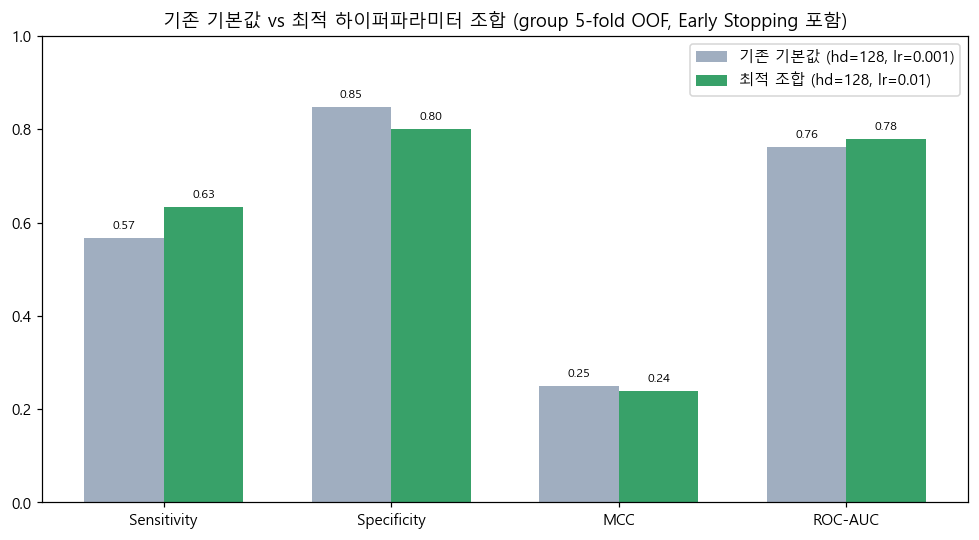

In [7]:
metrics = ["sensitivity", "specificity", "mcc", "roc_auc"]
metric_labels = ["Sensitivity", "Specificity", "MCC", "ROC-AUC"]

fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(metrics))
w = 0.35
base_vals = [results[baseline_key][m] for m in metrics]
best_vals = [results[best_key][m] for m in metrics]
ax.bar(x - w/2, base_vals, width=w, label=f"기존 기본값 (hd={baseline_key[0]}, lr={baseline_key[1]})", color="#a0aec0")
ax.bar(x + w/2, best_vals, width=w, label=f"최적 조합 (hd={best_key[0]}, lr={best_key[1]})", color="#38a169")
ax.set_xticks(x); ax.set_xticklabels(metric_labels)
ax.set_ylim(0, 1.0)
ax.set_title("기존 기본값 vs 최적 하이퍼파라미터 조합 (group 5-fold OOF, Early Stopping 포함)")
ax.legend()
for i, (b, v) in enumerate(zip(base_vals, best_vals)):
    ax.text(i - w/2, b + 0.02, f"{b:.2f}", ha="center", fontsize=8)
    ax.text(i + w/2, v + 0.02, f"{v:.2f}", ha="center", fontsize=8)
plt.tight_layout()
plt.show()

## 정리

- Early Stopping 위에서 hidden_dim x learning_rate 9개 조합을 group 5-fold로 공정 비교했습니다.
- 판단 기준은 동일하게 Sensitivity·Specificity 균형 + MCC.
- 평균 종료 epoch 히트맵으로 "learning rate가 너무 커서 비정상적으로 빨리 멈추는 조합"을 함께 확인할 수 있습니다.
- 최적 조합을 `train.py --hidden-dim <값> --lr <값>`으로 바로 적용할 수 있습니다.